<a href="https://colab.research.google.com/github/Thedreamaker/Qiskit_Learning/blob/basics/basics_entanglement/Qiskit_entanglement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit qiskit-aer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.5 MB/s eta 0:00:00


Measurement Results: {'111': 483, '000': 541}


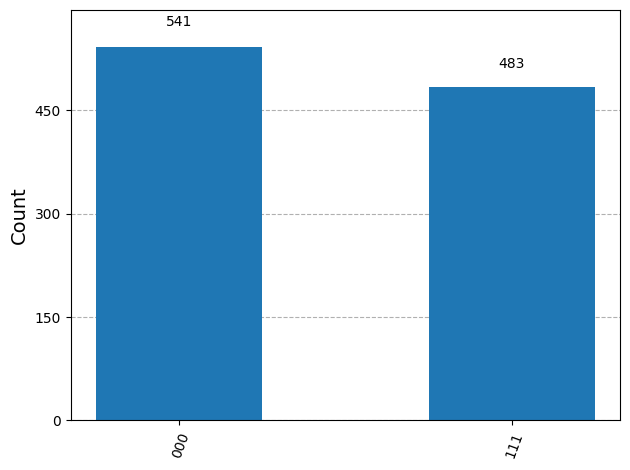

In [4]:
#%%writefile quantum_research.py
# ==========================================
# QUANTUM INFORMATION RESEARCH PORTFOLIO
# FILE: quantum_research.py
# PROJECT: 3-QUBIT GHZ STATE WITH PHASE FLIP
# ==========================================




from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
from IPython.display import display

#def run_quantum_experiment():
#from qiskit.visualization import plot_histogram

# Step 2: Create a Quantum Circuit with 2 qubits and 3 classical bits
# The classical bits are used to store the measurement data at the end
qc = QuantumCircuit(3, 3)

# Step 3: Apply a Hadamard Gate (H) to the first qubit (qubit 0)
# This puts qubit 0 into a state of "Superposition" (50% chance of 0, 50% chance of 1)
qc.h(0)
qc.z(0)

# Step 4: Apply a Controlled-NOT Gate (CNOT)
# This hooks qubit 0 (control) up to qubit 1 (target).
# This step creates the "Quantum Entanglement" between the two particles.
qc.cx(0, 1)
qc.cx(1,2)
# Step 5: Measure both qubits and store the results in the classical bits
qc.measure([0, 1, 2], [0, 1, 2])

# Step 6: Use the local AerSimulator to test the circuit
# This mimics how a real quantum computer behaves
simulator = AerSimulator()
pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)
compiled_circuit = pm.run(qc)
#compiled_circuit = transpile(qc, simulator) # Prepares the circuit for the chip

# Step 7: Run the circuit 1024 times to gather statistics
job = simulator.run(compiled_circuit, shots=1024)
result = job.result()

# Step 8: Get the results (counts of how many times 00 or 11 appeared)
counts = result.get_counts()
print("Measurement Results:", counts)
#from IPython.display import display

# Create the figure object explicitly
fig = plot_histogram(counts)

# Force Colab to output the canvas inline
display(fig)
#plot_histogram(counts)
#plt.show()
# This wrapper allows the script to be safely imported or executed directly
#if __name__ == "__main__":
  #  run_quantum_experiment()